<a href="https://colab.research.google.com/github/wadeea23/Facial-Emotion-Recognition.lab/blob/main/wadeea_lab_NN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [54]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import zipfile
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras.utils import to_categorical
from keras.models import Sequential
from keras.layers import Dense, Input, Activation, Flatten
from keras.callbacks import EarlyStopping
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


**part 1**

In [55]:
zip_path="/content/labNN.zip"
extract_path="/content/labNN"
with zipfile.ZipFile(zip_path,"r") as zip_ref:
  zip_ref.extractall(extract_path)
print(os.listdir(extract_path))

['train', 'test']


In [56]:
train_path = os.path.join(extract_path, "train")
test_path = os.path.join(extract_path, "test")
print(os.listdir(train_path))
print(os.listdir(test_path))

['neutral', 'surprise', 'angry', 'happy', 'disgust', 'sad', 'fear']
['neutral', 'surprise', 'angry', 'happy', 'disgust', 'sad', 'fear']


In [57]:
emotions = os.listdir(train_path) ## to known every feeling how many pic in thair
for i in emotions:
    print(i, len(os.listdir(os.path.join(train_path, i))))

neutral 4965
surprise 3171
angry 3995
happy 7215
disgust 436
sad 4830
fear 4097


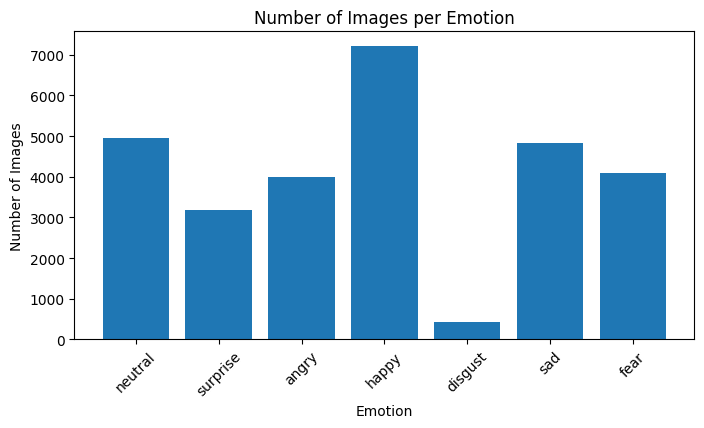

In [58]:
plt.figure(figsize=(8, 4))
plt.bar(emotions, [
    len(os.listdir(os.path.join(train_path, i)))
    for i in emotions])

plt.title("Number of Images per Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.show()

In [59]:
x_train, x_test, y_train, y_test = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

In [60]:
x_train = [] ## preprocessing & understand data to read the data for step 2
y_train = []

for i in os.listdir(train_path):
    for j in os.listdir(os.path.join(train_path, i)):
        img = Image.open(os.path.join(train_path, i, j)).convert("L")
        x_train.append(np.array(img))
        y_train.append(i)

x_train = np.array(x_train)
y_train = np.array(y_train)

print(x_train.shape)
print(y_train.shape)
print('img_dim',x_train.shape[1:])

(28709, 48, 48)
(28709,)
img_dim (48, 48)


In [61]:
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_train = to_categorical(y_train)
print(y_train.shape)

(28709, 7)


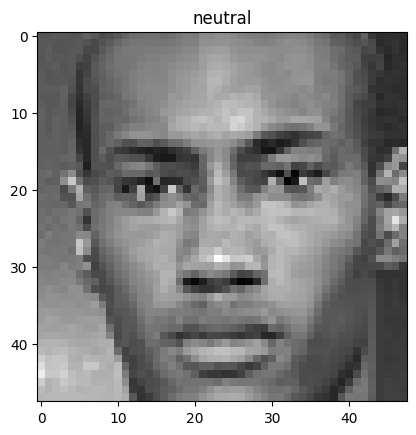

In [62]:
plt.imshow(x_train[0], cmap='gray')
plt.title(le.classes_[np.argmax(y_train[0])])
plt.show()

In [63]:
x_train = x_train / 255

**PART 2**
Neural Network

In [64]:
model = Sequential()
model.add(Input(shape=(48, 48)))
model.add(Flatten())
model.add(Dense(128))
model.add(Activation('relu'))
model.add(Dense(7))
model.add(Activation('softmax'))


In [65]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 7)              │           903 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 7)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 295,943 (1.13 MB)

 Trainable params: 295,943 (1.13 MB)

 Non-trainable params: 0 (0.00 B)

In [66]:
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [67]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2)

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.3490 - loss: 1.5889 - val_accuracy: 1.7416e-04 - val_loss: 8.3621
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4056 - loss: 1.4892 - val_accuracy: 0.0122 - val_loss: 9.3171
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4159 - loss: 1.4690 - val_accuracy: 0.0138 - val_loss: 9.9337
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.4221 - loss: 1.4509 - val_accuracy: 0.0282 - val_loss: 9.7929
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.4321 - loss: 1.4331 - val_accuracy: 0.0127 - val_loss: 13.0039
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.4333 - loss: 1.4216 - val_accuracy: 0.0524 - val_loss: 11.7266
Epoch 7/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4422 - loss: 1.4081 - val_accuracy: 0.0374 - val_loss: 11.4360
Epoch 8/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4439 - loss: 1.4039 - val_acc

<Axes: >

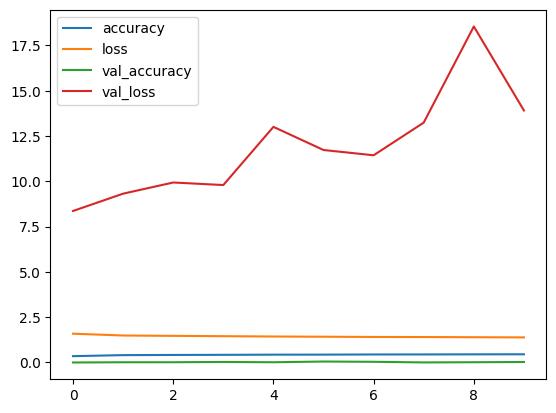

In [68]:
pd.DataFrame(history.history).plot()

In [69]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3839 - loss: 3.8084
Test Accuracy: 0.3839455842971802
Test Loss: 3.8084144592285156


In [70]:
y_pred = model.predict(x_test)
y_pred = np.argmax(y_pred, axis=1)
y_true = np.argmax(y_test, axis=1)

115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [71]:
accuracy_score(y_true, y_pred)

0.3839455782312925

In [72]:
classification_report(y_true, y_pred)

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


'              precision    recall  f1-score   support\n\n           0       0.34      0.19      0.24       511\n           1       0.00      0.00      0.00        56\n           2       0.00      0.00      0.00       524\n           3       0.44      0.75      0.56       924\n           4       0.30      0.52      0.38       636\n           5       0.30      0.11      0.16       618\n           6       0.45      0.55      0.50       406\n\n    accuracy                           0.38      3675\n   macro avg       0.26      0.30      0.26      3675\nweighted avg       0.31      0.38      0.32      3675\n'

In [73]:
confusion_matrix(y_true, y_pred)

array([[ 96,   0,   0, 165, 161,  40,  49],
       [  6,   0,   0,  26,  13,   5,   6],
       [ 56,   0,   0, 186, 158,  28,  96],
       [ 26,   0,   0, 692, 145,  30,  31],
       [ 32,   0,   0, 190, 333,  44,  37],
       [ 56,   0,   0, 214, 231,  68,  49],
       [ 10,   0,   0,  84,  77,  13, 222]])

**part 3 **

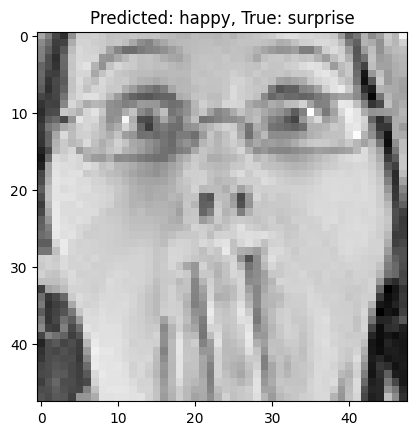

In [74]:
errors = np.where(y_pred != y_true)
for i in errors[0]:
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Predicted: {le.classes_[y_pred[i]]}, True: {le.classes_[y_true[i]]}")

The model made mistakes because some emotions look similar. Some images may also be unclear or have different lighting.

In [75]:
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

In [76]:
history = model.fit(x_train, y_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping])

Epoch 1/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4574 - loss: 1.3792 - val_accuracy: 0.0106 - val_loss: 16.5998
Epoch 2/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4602 - loss: 1.3740 - val_accuracy: 0.0355 - val_loss: 17.9840
Epoch 3/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 7s 10ms/step - accuracy: 0.4587 - loss: 1.3691 - val_accuracy: 0.0026 - val_loss: 22.3889
Epoch 4/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4626 - loss: 1.3616 - val_accuracy: 0.0256 - val_loss: 20.2368
Epoch 5/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4645 - loss: 1.3554 - val_accuracy: 0.0117 - val_loss: 19.9833
Epoch 6/10
718/718 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.4669 - loss: 1.3520 - val_accuracy: 0.0320 - val_loss: 21.0925


In [77]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

115/115 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3850 - loss: 4.3262
Test Accuracy: 0.3850340247154236
Test Loss: 4.326170921325684


**part 4**

In [78]:
%%writefile /content/app.py
model.save("emotion_model.keras")
with open("emotion_classes.json", "w") as f:
    json.dump(le.classes_.tolist(), f)

files.download("emotion_model.keras")
files.download("emotion_classes.json")


Overwriting /content/app.py


In [79]:
!pip install streamlit pyngrok

In [80]:
%%writefile /content/app.py
import streamlit as st
import numpy as np
import pickle
from PIL import Image
from tensorflow.keras.models import load_model

# Load the trained model
model = load_model("/content/emotion_model.keras")

# Load emotion names
with open("/content/emotion_classes.pkl", "rb") as f:
    classes = pickle.load(f)

# App title
st.title("Facial Emotion Detector")
st.write("Upload an image or take a photo to predict the emotion.")

# Select image
uploaded_image = st.file_uploader(
    "Upload an Image",
    type=["jpg", "jpeg", "png"]
)

camera_image = st.camera_input("Or Take a Photo")

if uploaded_image is not None:
    image_file = uploaded_image
else:
    image_file = camera_image

# Display and predict
if image_file is not None:

    image = Image.open(image_file)
    st.image(image, caption="Your Image", width=300)

    if st.button("Predict Emotion"):

        # Prepare image
        image = image.convert("L")
        image = image.resize((48, 48))

        image = np.array(image) / 255.0
        image = np.expand_dims(image, axis=0)

        # Predict
        prediction = model.predict(image, verbose=0)[0]
        best_index = np.argmax(prediction)

        # Show result
        st.subheader("Predicted Emotion")
        st.success(classes[best_index].capitalize())

        # Show probabilities
        st.subheader("Emotion Probabilities")

        for i in range(len(classes)):
            st.write(classes[i].capitalize())
            st.progress(float(prediction[i]))
            st.write(f"{prediction[i] * 100:.2f}%")

st.divider()
st.caption("Neural Network Project")


Overwriting /content/app.py


In [81]:
!streamlit run /content/app.py --server.port 8501 --server.headless true --server.enableCORS false --server.enableXsrfProtection false > /content/log.txt 2>&1 &

In [82]:
from google.colab import output

output.serve_kernel_port_as_iframe(8501)

<IPython.core.display.Javascript object>